# 📦 Bounding Box, Unary Union ve Boş Alan Hesaplama Rehberi

Bu notebook şunları kapsar:
1. **Bounding Box (Sınır Kutusu)** - `.bounds` ve axis-aligned bounding box
2. **Unary Union** - Birden fazla geometriyi birleştirme
3. **Difference** - Boş alan hesaplama
4. **Edge Cases** - Özel durumlar ve dikkat edilmesi gerekenler
5. **Yarışma İçin Pratik Kullanım**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon as MplPolygon
from shapely.geometry import Polygon, Point, box, MultiPolygon
from shapely.ops import unary_union
from shapely import affinity

# Görselleştirme yardımcı fonksiyonu
def plot_geometries(geometries, labels=None, colors=None, 
                    show_bounds=False, show_union=False,
                    title="", figsize=(10, 8)):
    """
    Birden fazla geometriyi görselleştirir.
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    if colors is None:
        colors = plt.cm.Set2(np.linspace(0, 1, len(geometries)))
    
    if labels is None:
        labels = [f'Şekil {i+1}' for i in range(len(geometries))]
    
    all_geoms = []
    
    for i, (geo, label, color) in enumerate(zip(geometries, labels, colors)):
        if hasattr(geo, 'exterior'):
            x, y = geo.exterior.xy
            ax.fill(x, y, alpha=0.5, color=color, label=label)
            ax.plot(x, y, color=color, linewidth=2)
            all_geoms.append(geo)
        elif hasattr(geo, 'geoms'):
            for g in geo.geoms:
                x, y = g.exterior.xy
                ax.fill(x, y, alpha=0.5, color=color)
                ax.plot(x, y, color=color, linewidth=2)
                all_geoms.append(g)
    
    if show_bounds and all_geoms:
        union = unary_union(all_geoms)
        minx, miny, maxx, maxy = union.bounds
        width = maxx - minx
        height = maxy - miny
        
        # Dikdörtgen bounding box
        rect = Rectangle((minx, miny), width, height,
                         fill=False, edgecolor='red', linewidth=2,
                         linestyle='--', label=f'Bounds (Dikdörtgen)\n{width:.2f} x {height:.2f}')
        ax.add_patch(rect)
        
        # Kare bounding box (yarışma için)
        side = max(width, height)
        cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
        square = Rectangle((cx - side/2, cy - side/2), side, side,
                           fill=False, edgecolor='blue', linewidth=2,
                           linestyle=':', label=f'Kare BBox\nKenar={side:.2f}')
        ax.add_patch(square)
    
    if show_union and len(all_geoms) > 1:
        union = unary_union(all_geoms)
        if hasattr(union, 'exterior'):
            x, y = union.exterior.xy
            ax.plot(x, y, 'k-', linewidth=3, label='Unary Union', alpha=0.7)
    
    ax.set_aspect('equal')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("✅ Görselleştirme fonksiyonları hazır!")

✅ Görselleştirme fonksiyonları hazır!


---
## 1️⃣ Bounding Box Temelleri

`.bounds` property'si **Axis-Aligned Bounding Box (AABB)** döndürür:
- Her zaman dikdörtgen (kare değil)
- Eksenlere paralel kenarlar

=== BOUNDS ÖZELLİKLERİ ===
Bounds: (0.0, 0.0, 4.0, 3.0)
Min X: 0.0, Max X: 4.0
Min Y: 0.0, Max Y: 3.0
Genişlik: 4.0
Yükseklik: 3.0

⚠️ DİKKAT: Dikdörtgen, kare DEĞİL!


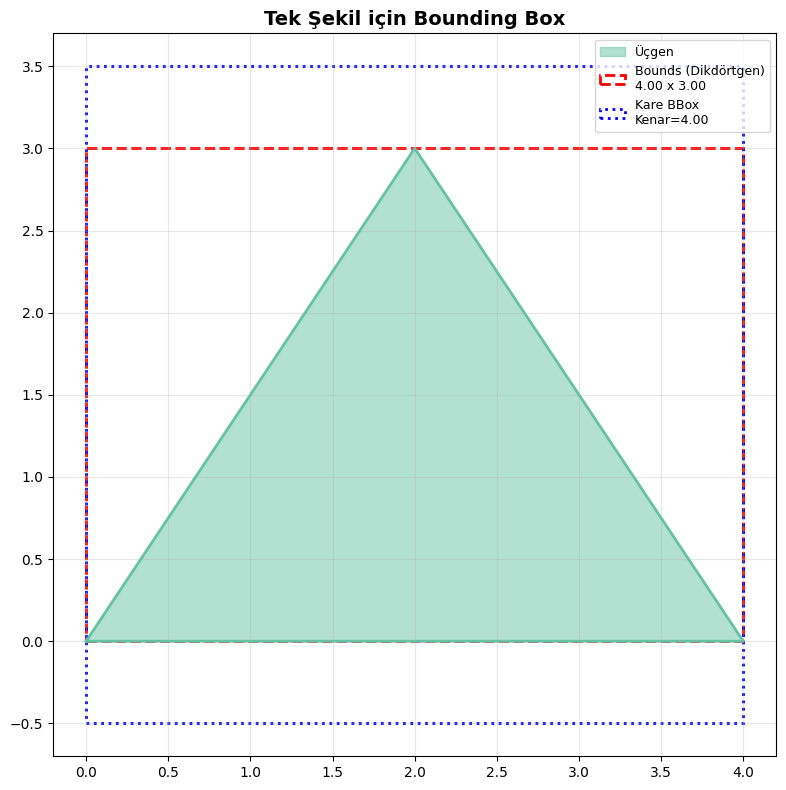

In [2]:
# Basit bir üçgen
ucgen = Polygon([(0, 0), (4, 0), (2, 3)])

# Bounds değerleri
minx, miny, maxx, maxy = ucgen.bounds

print("=== BOUNDS ÖZELLİKLERİ ===")
print(f"Bounds: {ucgen.bounds}")
print(f"Min X: {minx}, Max X: {maxx}")
print(f"Min Y: {miny}, Max Y: {maxy}")
print(f"Genişlik: {maxx - minx}")
print(f"Yükseklik: {maxy - miny}")
print(f"\n⚠️ DİKKAT: Dikdörtgen, kare DEĞİL!")

plot_geometries([ucgen], ['Üçgen'], show_bounds=True,
                title='Tek Şekil için Bounding Box')

### 1.1 Kare vs Dikdörtgen Bounding Box

=== DİKDÖRTGEN vs KARE ===
Dikdörtgen Bounds: 8.0 x 2.0 = 16.0 birim²
Kare BBox: 8.0 x 8.0 = 64.0 birim²

⚠️ Kare bbox 4.0x daha büyük alan kaplar!


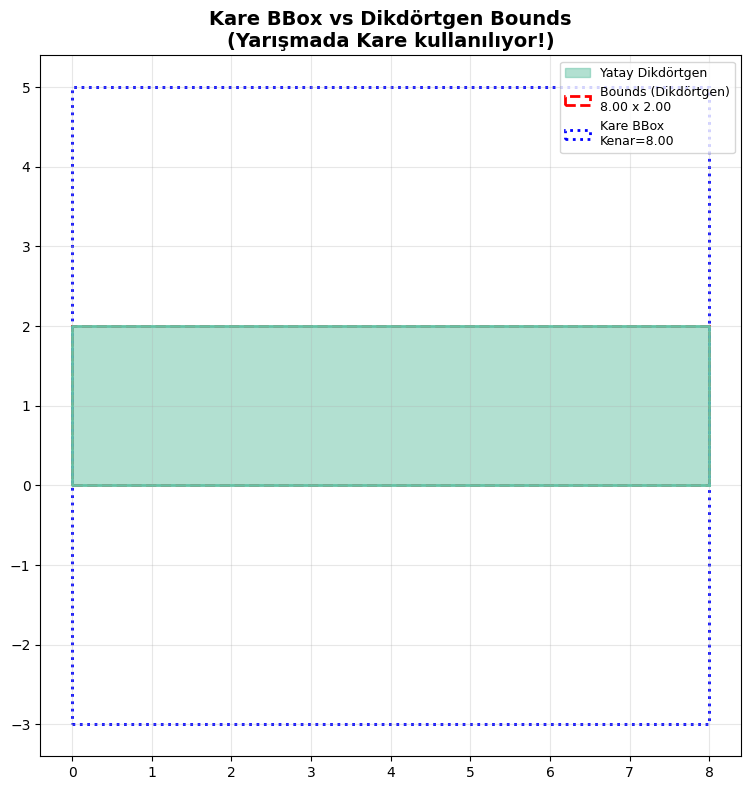

In [3]:
# Yatay uzun bir şekil
yatay = box(0, 0, 8, 2)  # 8x2 dikdörtgen

minx, miny, maxx, maxy = yatay.bounds
width = maxx - minx
height = maxy - miny
side = max(width, height)  # Kare için

print("=== DİKDÖRTGEN vs KARE ===")
print(f"Dikdörtgen Bounds: {width:.1f} x {height:.1f} = {width * height:.1f} birim²")
print(f"Kare BBox: {side:.1f} x {side:.1f} = {side * side:.1f} birim²")
print(f"\n⚠️ Kare bbox {(side*side)/(width*height):.1f}x daha büyük alan kaplar!")

plot_geometries([yatay], ['Yatay Dikdörtgen'], show_bounds=True,
                title='Kare BBox vs Dikdörtgen Bounds\n(Yarışmada Kare kullanılıyor!)')

---
## 2️⃣ Unary Union - Geometri Birleştirme

`unary_union()` birden fazla geometriyi tek geometriye birleştirir.

### 2.1 Kesişen Geometriler (Overlapping)

=== KESİŞEN GEOMETRİLER ===
Kare 1 Alanı: 9.0
Kare 2 Alanı: 9.0
Toplam (ayrı): 18.0
Union Alanı: 17.0

🔍 Union tipi: Polygon
→ Kesişen parçalar birleşti, TEK Polygon oluştu!


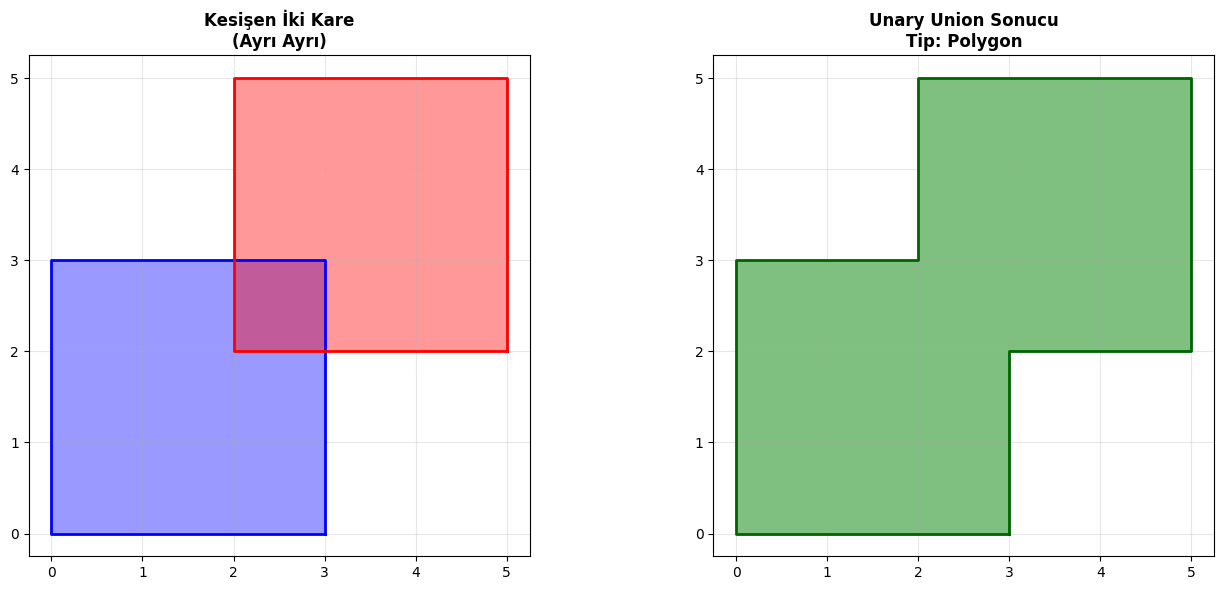

In [4]:
# Kesişen iki kare
kare1 = box(0, 0, 3, 3)
kare2 = box(2, 2, 5, 5)

# Union
union = unary_union([kare1, kare2])

print("=== KESİŞEN GEOMETRİLER ===")
print(f"Kare 1 Alanı: {kare1.area}")
print(f"Kare 2 Alanı: {kare2.area}")
print(f"Toplam (ayrı): {kare1.area + kare2.area}")
print(f"Union Alanı: {union.area}")
print(f"\n🔍 Union tipi: {union.geom_type}")
print(f"→ Kesişen parçalar birleşti, TEK Polygon oluştu!")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sol: Ayrı ayrı
ax = axes[0]
for geo, color in [(kare1, 'blue'), (kare2, 'red')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.4, color=color)
    ax.plot(x, y, color=color, linewidth=2)
ax.set_aspect('equal')
ax.set_title('Kesişen İki Kare\n(Ayrı Ayrı)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Sağ: Union
ax = axes[1]
x, y = union.exterior.xy
ax.fill(x, y, alpha=0.5, color='green')
ax.plot(x, y, color='darkgreen', linewidth=2)
ax.set_aspect('equal')
ax.set_title(f'Unary Union Sonucu\nTip: {union.geom_type}', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.2 Ayrık Geometriler (Disjoint) - ⚠️ ÖNEMLİ EDGE CASE

=== AYRIK GEOMETRİLER (EDGE CASE!) ===
🔍 Union tipi: MultiPolygon
→ Ayrık geometriler BİRLEŞMEZ, MultiPolygon olur!

Parça sayısı: 3
Toplam Alan: 4.50


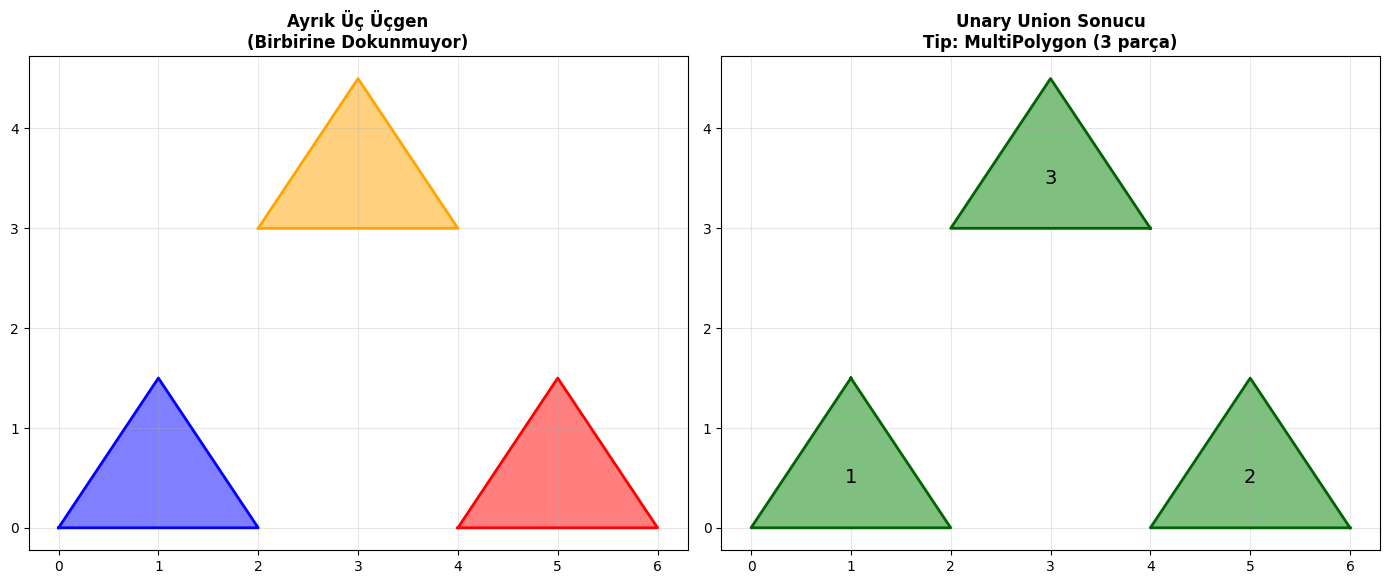

In [5]:
# Birbirine DOKUNMAYAN üç üçgen
ucgen1 = Polygon([(0, 0), (2, 0), (1, 1.5)])
ucgen2 = Polygon([(4, 0), (6, 0), (5, 1.5)])
ucgen3 = Polygon([(2, 3), (4, 3), (3, 4.5)])

# Union
union = unary_union([ucgen1, ucgen2, ucgen3])

print("=== AYRIK GEOMETRİLER (EDGE CASE!) ===")
print(f"🔍 Union tipi: {union.geom_type}")
print(f"→ Ayrık geometriler BİRLEŞMEZ, MultiPolygon olur!")
print(f"\nParça sayısı: {len(union.geoms)}")
print(f"Toplam Alan: {union.area:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sol: Ayrı ayrı
ax = axes[0]
for geo, color in [(ucgen1, 'blue'), (ucgen2, 'red'), (ucgen3, 'orange')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.5, color=color)
    ax.plot(x, y, color=color, linewidth=2)
ax.set_aspect('equal')
ax.set_title('Ayrık Üç Üçgen\n(Birbirine Dokunmuyor)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Sağ: Union (MultiPolygon)
ax = axes[1]
for i, geo in enumerate(union.geoms):
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.5, color='green')
    ax.plot(x, y, color='darkgreen', linewidth=2)
    # Parça numarası
    cx, cy = geo.centroid.x, geo.centroid.y
    ax.text(cx, cy, f'{i+1}', fontsize=14, ha='center', va='center')
ax.set_aspect('equal')
ax.set_title(f'Unary Union Sonucu\nTip: {union.geom_type} ({len(union.geoms)} parça)', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3 Dokunan Geometriler (Touching)

=== DOKUNAN GEOMETRİLER ===
Dokunuyor mu? True
Kesişiyor mu (iç içe geçiyor mu)? False

🔍 Union tipi: Polygon
→ Dokunan geometriler BİRLEŞİR!


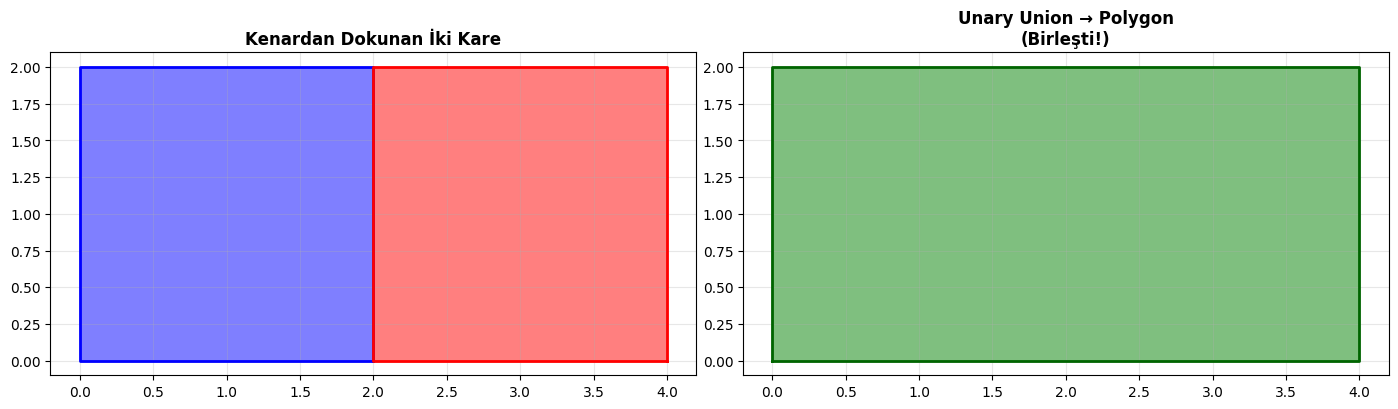

In [6]:
# Sadece kenardan DOKUNAN iki kare
kare1 = box(0, 0, 2, 2)
kare2 = box(2, 0, 4, 2)  # Tam kenardan dokunuyor

# Union
union = unary_union([kare1, kare2])

print("=== DOKUNAN GEOMETRİLER ===")
print(f"Dokunuyor mu? {kare1.touches(kare2)}")
print(f"Kesişiyor mu (iç içe geçiyor mu)? {kare1.intersects(kare2) and not kare1.touches(kare2)}")
print(f"\n🔍 Union tipi: {union.geom_type}")
print(f"→ Dokunan geometriler BİRLEŞİR!")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sol: Ayrı
ax = axes[0]
for geo, color in [(kare1, 'blue'), (kare2, 'red')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.5, color=color)
    ax.plot(x, y, color=color, linewidth=2)
ax.set_aspect('equal')
ax.set_title('Kenardan Dokunan İki Kare', fontweight='bold')
ax.grid(True, alpha=0.3)

# Sağ: Union
ax = axes[1]
x, y = union.exterior.xy
ax.fill(x, y, alpha=0.5, color='green')
ax.plot(x, y, color='darkgreen', linewidth=2)
ax.set_aspect('equal')
ax.set_title(f'Unary Union → {union.geom_type}\n(Birleşti!)', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3️⃣ Boş Alan Hesaplama (Difference)

Bounding Box - Shapes = Boş Alan

=== BOŞ ALAN HESAPLAMA ===
Şekillerin toplam alanı: 6.00
Kare BBox alanı: 36.00
Boş alan: 30.00
Doluluk oranı: 16.7%

🔍 Boş alan tipi: Polygon


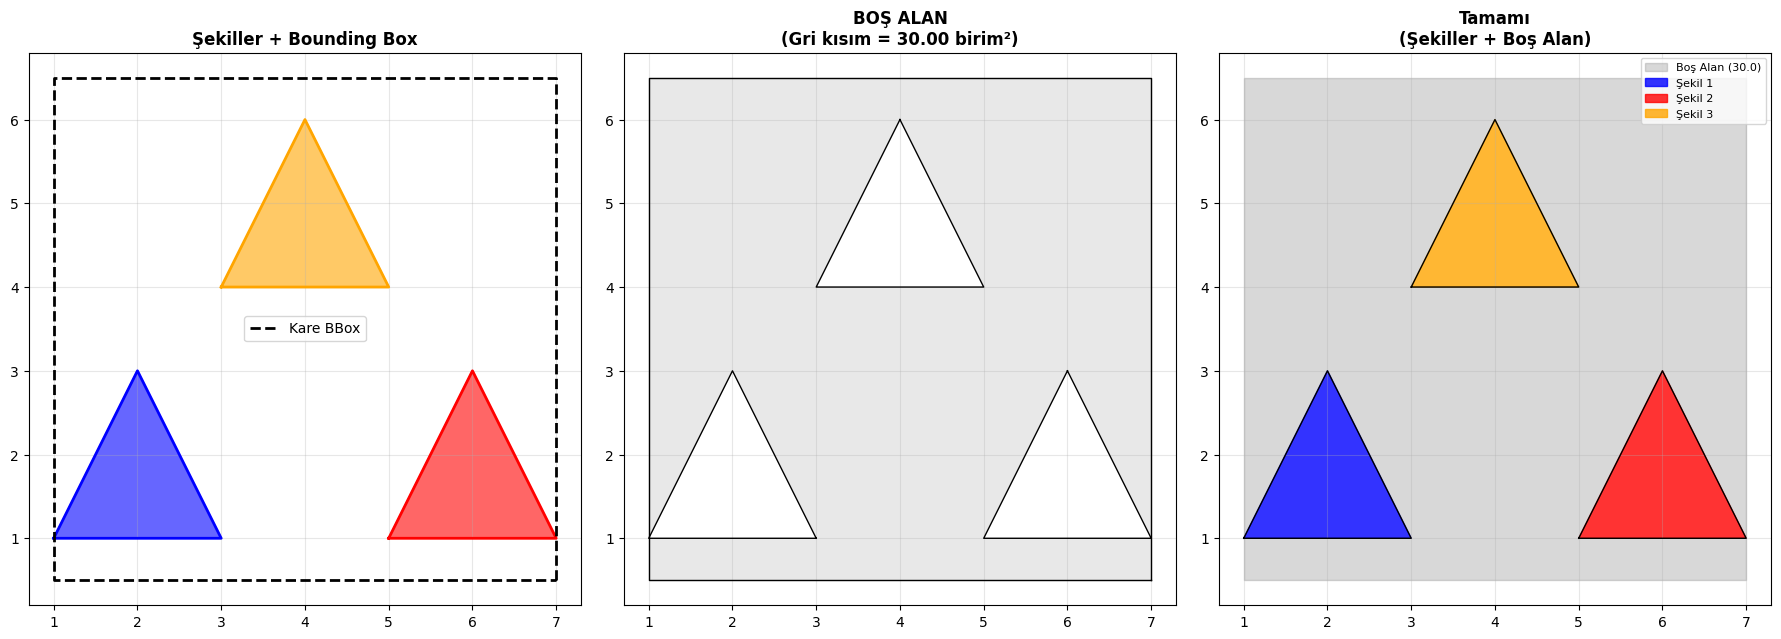

In [7]:
# Üç ayrık şekil
sekil1 = Polygon([(1, 1), (3, 1), (2, 3)])
sekil2 = Polygon([(5, 1), (7, 1), (6, 3)])
sekil3 = Polygon([(3, 4), (5, 4), (4, 6)])

tumsu = unary_union([sekil1, sekil2, sekil3])

# Bounding box (kare olarak)
minx, miny, maxx, maxy = tumsu.bounds
side = max(maxx - minx, maxy - miny)
cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
kare_bbox = box(cx - side/2, cy - side/2, cx + side/2, cy + side/2)

# BOŞ ALAN = BBox - Şekiller
bos_alan = kare_bbox.difference(tumsu)

print("=== BOŞ ALAN HESAPLAMA ===")
print(f"Şekillerin toplam alanı: {tumsu.area:.2f}")
print(f"Kare BBox alanı: {kare_bbox.area:.2f}")
print(f"Boş alan: {bos_alan.area:.2f}")
print(f"Doluluk oranı: {tumsu.area / kare_bbox.area * 100:.1f}%")
print(f"\n🔍 Boş alan tipi: {bos_alan.geom_type}")

# Görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Sol: Şekiller + BBox
ax = axes[0]
for geo, color in [(sekil1, 'blue'), (sekil2, 'red'), (sekil3, 'orange')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.6, color=color)
    ax.plot(x, y, color=color, linewidth=2)
bx, by = kare_bbox.exterior.xy
ax.plot(bx, by, 'k--', linewidth=2, label='Kare BBox')
ax.set_aspect('equal')
ax.set_title('Şekiller + Bounding Box', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Orta: Boş alan
ax = axes[1]
if hasattr(bos_alan, 'exterior'):
    x, y = bos_alan.exterior.xy
    ax.fill(x, y, alpha=0.5, color='lightgray')
    ax.plot(x, y, 'k-', linewidth=1)
    # İç delikleri göster
    for interior in bos_alan.interiors:
        ix, iy = interior.xy
        ax.fill(ix, iy, color='white')
        ax.plot(ix, iy, 'k-', linewidth=1)
ax.set_aspect('equal')
ax.set_title(f'BOŞ ALAN\n(Gri kısım = {bos_alan.area:.2f} birim²)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Sağ: Birlikte
ax = axes[2]
# Boş alanı gri olarak
if hasattr(bos_alan, 'exterior'):
    x, y = bos_alan.exterior.xy
    ax.fill(x, y, alpha=0.3, color='gray', label=f'Boş Alan ({bos_alan.area:.1f})')
    for interior in bos_alan.interiors:
        ix, iy = interior.xy
        ax.fill(ix, iy, color='white')
# Şekilleri üzerine çiz
for geo, color, name in [(sekil1, 'blue', 'Şekil 1'), 
                          (sekil2, 'red', 'Şekil 2'), 
                          (sekil3, 'orange', 'Şekil 3')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.8, color=color, label=name)
    ax.plot(x, y, color='black', linewidth=1)
ax.set_aspect('equal')
ax.set_title('Tamamı\n(Şekiller + Boş Alan)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4️⃣ Edge Cases ve Dikkat Edilmesi Gerekenler

### 4.1 Edge Case: Tek Nokta Dokunma

=== TEK NOKTA DOKUNMA ===
Touches: True
Union tipi: MultiPolygon
→ Parça sayısı: 2


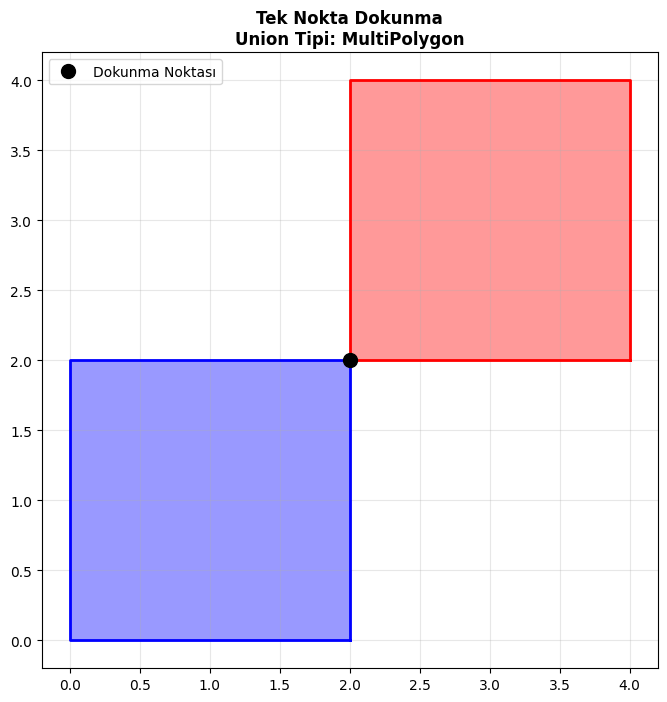

In [8]:
# Sadece köşeden dokunan iki kare
kare1 = box(0, 0, 2, 2)
kare2 = box(2, 2, 4, 4)  # Sadece (2,2) noktasında dokunuyor

union = unary_union([kare1, kare2])

print("=== TEK NOKTA DOKUNMA ===")
print(f"Touches: {kare1.touches(kare2)}")
print(f"Union tipi: {union.geom_type}")

# Dikkat: Tek noktadan dokunma da birleştiriyor!
if union.geom_type == 'Polygon':
    print("→ TEK NOKTADAN dokunma bile BİRLEŞTİRİR!")
else:
    print(f"→ Parça sayısı: {len(union.geoms)}")

fig, ax = plt.subplots(figsize=(8, 8))
for geo, color in [(kare1, 'blue'), (kare2, 'red')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.4, color=color)
    ax.plot(x, y, color=color, linewidth=2)
ax.plot(2, 2, 'ko', markersize=10, label='Dokunma Noktası')
ax.set_aspect('equal')
ax.legend()
ax.set_title(f'Tek Nokta Dokunma\nUnion Tipi: {union.geom_type}', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.show()

### 4.2 Edge Case: Polygon with Hole (Delikli Çokgen)

=== DELİKLİ ÇOKGEN ===
Tip: Polygon
Dış alan: 36.0
İç alan (delik): 4.0
Delikli alan: 32.0

İç halka sayısı (delik): 1


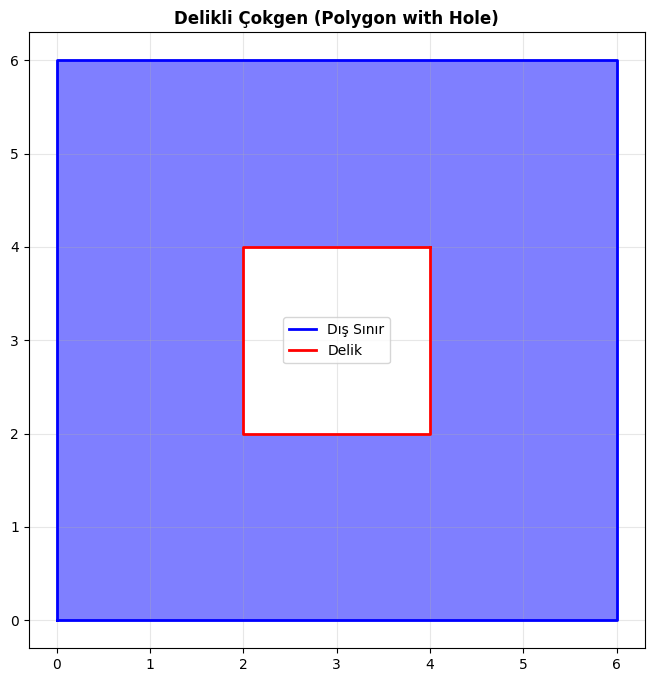

In [9]:
# Büyük kare ortasında küçük kare var
dis_kare = box(0, 0, 6, 6)
ic_kare = box(2, 2, 4, 4)

# Fark al → Delikli çokgen
delikli = dis_kare.difference(ic_kare)

print("=== DELİKLİ ÇOKGEN ===")
print(f"Tip: {delikli.geom_type}")
print(f"Dış alan: {dis_kare.area}")
print(f"İç alan (delik): {ic_kare.area}")
print(f"Delikli alan: {delikli.area}")
print(f"\nİç halka sayısı (delik): {len(list(delikli.interiors))}")

fig, ax = plt.subplots(figsize=(8, 8))

# Dış sınır
x, y = delikli.exterior.xy
ax.fill(x, y, alpha=0.5, color='blue')
ax.plot(x, y, 'b-', linewidth=2, label='Dış Sınır')

# İç sınır (delik)
for interior in delikli.interiors:
    ix, iy = interior.xy
    ax.fill(ix, iy, color='white')  # Deliği beyaz yap
    ax.plot(ix, iy, 'r-', linewidth=2, label='Delik')

ax.set_aspect('equal')
ax.legend()
ax.set_title('Delikli Çokgen (Polygon with Hole)', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.show()

### 4.3 Edge Case: Çok Küçük Gap (Neredeyse Dokunan)

=== ÇOK KÜÇÜK GAP ===
Gap: 0.001 birim
Touches: False
Distance: 0.001000
Union tipi: MultiPolygon
→ Küçük gap bile AYRIK tutar! Parça: 2


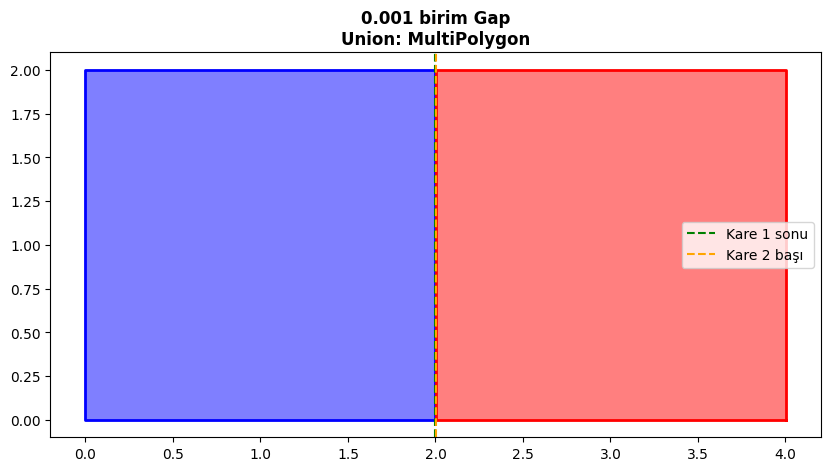

In [10]:
# Çok küçük boşlukla ayrılmış iki kare
kare1 = box(0, 0, 2, 2)
kare2 = box(2.001, 0, 4.001, 2)  # 0.001 birim gap

union = unary_union([kare1, kare2])

print("=== ÇOK KÜÇÜK GAP ===")
print(f"Gap: 0.001 birim")
print(f"Touches: {kare1.touches(kare2)}")
print(f"Distance: {kare1.distance(kare2):.6f}")
print(f"Union tipi: {union.geom_type}")

if union.geom_type == 'MultiPolygon':
    print(f"→ Küçük gap bile AYRIK tutar! Parça: {len(union.geoms)}")

# Görsel
fig, ax = plt.subplots(figsize=(10, 5))
for geo, color in [(kare1, 'blue'), (kare2, 'red')]:
    x, y = geo.exterior.xy
    ax.fill(x, y, alpha=0.5, color=color)
    ax.plot(x, y, color=color, linewidth=2)
ax.axvline(x=2, color='green', linestyle='--', label='Kare 1 sonu')
ax.axvline(x=2.001, color='orange', linestyle='--', label='Kare 2 başı')
ax.set_aspect('equal')
ax.legend()
ax.set_title(f'0.001 birim Gap\nUnion: {union.geom_type}', fontweight='bold')
plt.show()

### 4.4 Edge Case: Boş Liste ve Tek Eleman

In [11]:
# Boş liste
bos = unary_union([])
print("=== EDGE CASES ===")
print(f"Boş liste → Type: {bos.geom_type}, is_empty: {bos.is_empty}")

# Tek eleman
tek = unary_union([box(0, 0, 1, 1)])
print(f"Tek eleman → Type: {tek.geom_type}")

# Boş polygon'un bounds'u
print(f"\nBoş polygon bounds: {bos.bounds}")
print("⚠️ Boş polygon için bounds kontrolü yapmalısın!")

=== EDGE CASES ===
Boş liste → Type: GeometryCollection, is_empty: True
Tek eleman → Type: Polygon

Boş polygon bounds: (nan, nan, nan, nan)
⚠️ Boş polygon için bounds kontrolü yapmalısın!


---
## 5️⃣ Yarışma İçin Pratik Fonksiyonlar

In [12]:
def calculate_packing_metrics(polygons):
    """
    Santa 2025 yarışması için tüm metrikleri hesaplar.
    """
    if not polygons:
        return {
            'total_tree_area': 0,
            'bbox_area': 0,
            'bbox_side': 0,
            'empty_area': 0,
            'fill_ratio': 0,
            'score': 0
        }
    
    # Union
    union = unary_union(polygons)
    
    # Bounds
    minx, miny, maxx, maxy = union.bounds
    width = maxx - minx
    height = maxy - miny
    side = max(width, height)  # Kare bbox
    bbox_area = side ** 2
    
    # Alanlar
    total_tree_area = union.area
    empty_area = bbox_area - total_tree_area
    fill_ratio = total_tree_area / bbox_area if bbox_area > 0 else 0
    
    # Skor (yarışma formülü)
    score = 1.0 / side if side > 0 else 0
    
    return {
        'total_tree_area': total_tree_area,
        'bbox_width': width,
        'bbox_height': height,
        'bbox_side': side,
        'bbox_area': bbox_area,
        'empty_area': empty_area,
        'fill_ratio': fill_ratio,
        'score': score,
        'n_shapes': len(polygons)
    }

# Test
test_shapes = [
    box(0, 0, 2, 2),
    box(3, 0, 5, 2),
    box(1.5, 2.5, 3.5, 4.5)
]

metrics = calculate_packing_metrics(test_shapes)

print("=== PAKETLEME METRİKLERİ ===")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

=== PAKETLEME METRİKLERİ ===
total_tree_area: 12.0000
bbox_width: 5.0000
bbox_height: 4.5000
bbox_side: 5.0000
bbox_area: 25.0000
empty_area: 13.0000
fill_ratio: 0.4800
score: 0.2000
n_shapes: 3


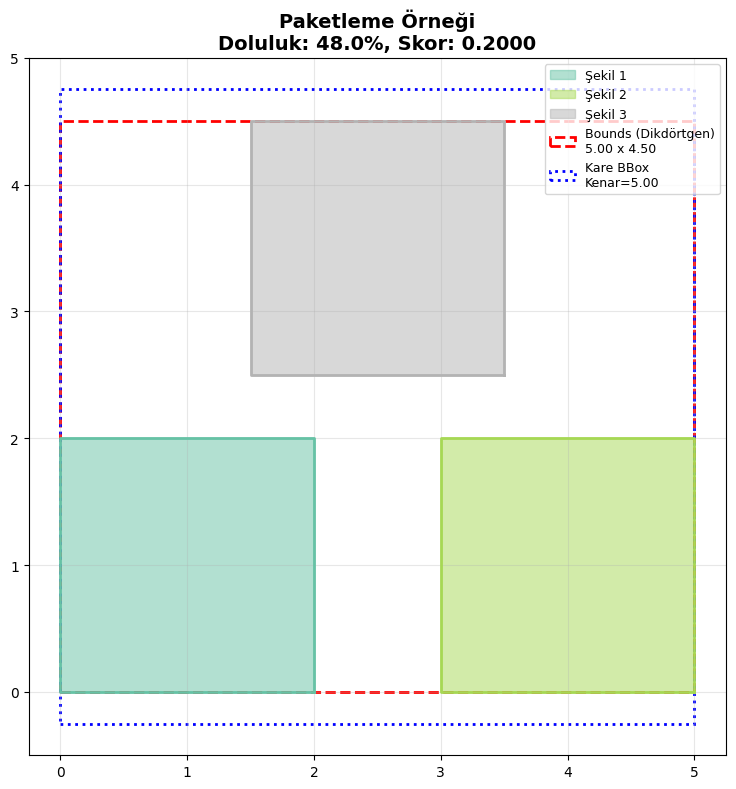

In [13]:
# Görselleştirme
plot_geometries(test_shapes, 
                ['Şekil 1', 'Şekil 2', 'Şekil 3'],
                show_bounds=True,
                title=f"Paketleme Örneği\nDoluluk: {metrics['fill_ratio']*100:.1f}%, Skor: {metrics['score']:.4f}")

---
## 📝 Özet Tablo

| Durum | `unary_union` Tipi | Açıklama |
|-------|-------------------|----------|
| Kesişen şekiller | `Polygon` | Birleşir |
| Kenardan dokunan | `Polygon` | Birleşir |
| Noktadan dokunan | `Polygon`* | Birleşir |
| Ayrık (gap var) | `MultiPolygon` | Ayrı kalır |
| Boş liste | `GeometryCollection` | Empty |
| Tek eleman | Orijinal tip | Değişmez |

**Yarışma İçin Önemli:**
- `bounds` → Dikdörtgen, `max(width, height)` → Kare
- Boş alan = `kare_bbox.difference(unary_union(trees))`
- Doluluk oranı = `tree_area / kare_bbox_area`

In [14]:
print("🎄 Tutorial Tamamlandı! 🎄")

🎄 Tutorial Tamamlandı! 🎄
